# Predicting body mass in Palmer Penguins

Can a random forest improve body mass prediction over ridge regression for adult Palmer Archipelago penguins? This notebook runs the design in [methodology.md](methodology.md), using [the accompanying CC0 dataset](https://github.com/allisonhorst/palmerpenguins/blob/main/inst/extdata/penguins.csv).

To rerun, open the notebook in Jupyter with `penguins.csv` beside it and run all cells. The recorded environment used Python 3.12, pandas 2.2.3, NumPy 2.3.5, scikit-learn 1.8.0, and Matplotlib 3.10.8.

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
raw = pd.read_csv(Path("penguins.csv"))

print(f"Raw dataset contains {raw.shape[0]} rows and {raw.shape[1]} fields.")
display(raw.isna().sum().rename("Missing values").to_frame())

Raw dataset contains 344 rows and 8 fields.


,Missing values
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0


## Clean the data and construct features

The bill ratio uses measurements from the same row and requires no statistics from other birds. Imputation, encoding, and scaling are fitted later within the training pipelines.

In [6]:
target = "body_mass_g"
measurements = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm"]
categorical = ["species", "sex"]

unique = raw.drop_duplicates()
clean = unique.loc[unique[target].gt(0)].copy()
clean[measurements] = clean[measurements].where(clean[measurements].gt(0))
clean["bill_ratio"] = clean["bill_length_mm"] / clean["bill_depth_mm"]

numeric = measurements + ["bill_ratio"]
X = clean[numeric + categorical]
y = clean[target]
assert target not in X.columns
assert np.isfinite(y).all()

print(f"Exact duplicates removed: {len(raw) - len(unique)}")
print(f"Missing or nonpositive targets removed: {len(unique) - len(clean)}")
print(f"Rows retained: {len(clean)}")
display(X.isna().sum().rename("Missing values after cleaning").to_frame())

Exact duplicates removed: 0
Missing or nonpositive targets removed: 2
Rows retained: 342


,Missing values after cleaning
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
bill_ratio,0
species,0
sex,9


## Split by species and define the models

The holdout shares the sampling frame with the training data. Species stratification keeps each species represented in the holdout and in each training validation fold.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=X["species"]
)
assert X_train.index.intersection(X_test.index).empty

counts = pd.DataFrame({
    "Training": X_train["species"].value_counts(),
    "Test": X_test["species"].value_counts(),
})
display(counts.sort_index())

def make_pipeline(regressor, *, scale_numeric=False):
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scale", StandardScaler()))

    category_steps = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="unknown")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    preprocessing = ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), numeric),
        ("category", category_steps, categorical),
    ])
    return Pipeline([("preprocess", preprocessing), ("regressor", regressor)])

models = {
    "Median baseline": DummyRegressor(strategy="median"),
    "Ridge regression": make_pipeline(Ridge(alpha=1.0), scale_numeric=True),
    "Random forest": make_pipeline(
        RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEED)
    ),
}

,Training,Test
species,,
Adelie,121,30
Chinstrap,54,14
Gentoo,98,25


## Compare models within the training set

Use the same five folds for all models. Scikit-learn returns negative error scores, so the table converts them back to positive values in grams.

In [8]:
splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(splitter.split(X_train, X_train["species"]))
scoring = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}

validation = {}
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=folds, scoring=scoring)
    fold_mae = -scores["test_mae"]
    validation[name] = {
        "Mean MAE (g)": fold_mae.mean(),
        "MAE fold SD (g)": fold_mae.std(ddof=1),
        "Mean RMSE (g)": -scores["test_rmse"].mean(),
    }

cv_table = pd.DataFrame.from_dict(validation, orient="index").sort_values("Mean MAE (g)")
preferred = cv_table.drop(index="Median baseline").index[0]
display(cv_table.round(1))
print(f"Preferred model by training validation MAE: {preferred}")

,Mean MAE (g),MAE fold SD (g),Mean RMSE (g)
Ridge regression,235.3,45.5,293.5
Random forest,246.7,40.6,312.0
Median baseline,671.6,99.2,812.0


Preferred model by training validation MAE: Ridge regression


## Evaluate on the holdout

Refit each fixed model on all training rows, then score its predictions on the same test rows. The diagonal in the plot marks exact agreement between observed and predicted mass.

In [9]:
test_results = {}
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)
    predictions[name] = predicted
    test_results[name] = {
        "MAE (g)": mean_absolute_error(y_test, predicted),
        "RMSE (g)": root_mean_squared_error(y_test, predicted),
    }

test_table = pd.DataFrame.from_dict(test_results, orient="index")
print(f"Holdout size: {len(y_test)} penguins")
display(test_table.round(1))

Holdout size: 69 penguins


,MAE (g),RMSE (g)
Median baseline,669.2,817.3
Ridge regression,236.8,287.3
Random forest,228.7,293.1


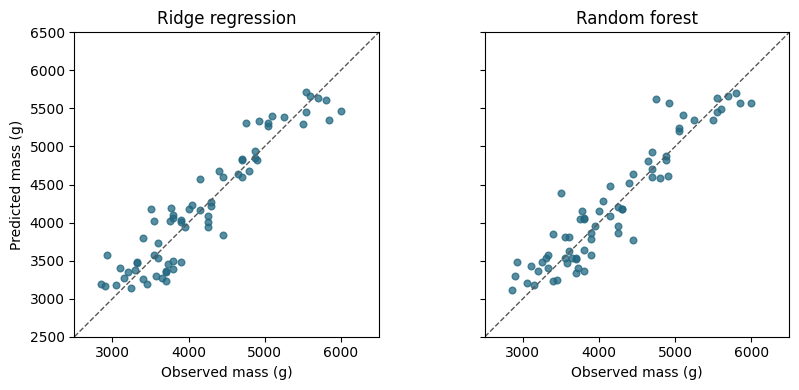

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
bounds = (2500, 6500)
for ax, name in zip(axes, ["Ridge regression", "Random forest"]):
    ax.scatter(y_test, predictions[name], s=23, color="#226780", alpha=0.75)
    ax.plot(bounds, bounds, color="#565656", linestyle="--", linewidth=1)
    ax.set(xlim=bounds, ylim=bounds, xlabel="Observed mass (g)", title=name)
    ax.set_aspect("equal")
axes[0].set_ylabel("Predicted mass (g)")
fig.tight_layout()
display(fig)
plt.close(fig)

## Findings and next steps

After cleaning, the experiment retained 342 penguins, including 69 in the held-out set. Ridge regression ranked first in training cross-validation, with mean MAE of 235.3 g. On the holdout, ridge regression and random forest achieved MAEs of 236.8 g and 228.7 g, respectively, compared with 669.2 g for the median baseline. The forest led on holdout MAE by 8.1 g, while ridge led on holdout RMSE (287.3 g versus 293.1 g), so the ranking depended on the metric and evaluation split. With more time, I would test the models on independently collected birds from other seasons and use paired resampling to estimate uncertainty in the difference in MAE. I would also repeat the comparison without recorded sex and without the bill ratio to measure how much each contributes.